# Chan et al. 2021 — Lung (SCLC) · 02 Manifold

Score the three embryonic modules (Gast/pSom/Crest) with the union control pool → graph-smooth for
geography → cell-cycle confound check → **honest topology test** (PPT tree fork-count vs curve) →
fit a curve with a fold diagnostic → root from the developmental order → pseudotime. The tree
over-forks a compact cloud (no single dominant Y) and Gast/pSom **co-vary** rather than compete, so
the geometry is **non-branching (Linear)** and a curve is the correct model.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load `processed.h5ad`; score modules; graph-smooth for geography

In [4]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_,s,vt = np.linalg.svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 50998 cells
UMAP principal-axis ratio (major/minor singular value): 1.62
Gast: 80/81 genes present
pSom: 96/98 genes present
Crest: 104/104 genes present
raw module means (honest readout): {'Gast': 0.0365, 'pSom': 0.1113, 'Crest': -0.0802}


### Module geography + cell-cycle confound
Smoothed spatial correlations: **Gast and pSom co-vary** (positive r) while both oppose Crest
(pSom↔Crest strongly negative) — an inverse terminal-Crest gradient, not a competitive
Gast/pSom bifurcation. Modules are **not** proliferation-confounded (|r| with cycling score small)
and the pSom↔Crest axis survives — indeed strengthens — in non-cycling cells, so the whole manifold
is kept (no scoping).

In [6]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')
print('per-compartment smoothed developmental means:')
print(adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
g2m = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0).values
g1s = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0).values
cyc = np.maximum(g1s, g2m)
print('module vs cycling score (Pearson):')
for m in ['Gast','pSom','Crest']:
    print(f'  {m}: r = {np.corrcoef(adata.obs[m], cyc)[0,1]:+.3f}')
noncyc = ~adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
r_all = np.corrcoef(adata.obs['pSom_sm'], adata.obs['Crest_sm'])[0,1]
r_nc  = np.corrcoef(adata.obs.loc[noncyc.values,'pSom_sm'], adata.obs.loc[noncyc.values,'Crest_sm'])[0,1]
r_gp  = np.corrcoef(adata.obs.loc[noncyc.values,'Gast_sm'], adata.obs.loc[noncyc.values,'pSom_sm'])[0,1]
print(f'  pSom<->Crest smoothed: all r={r_all:+.2f} | non-cycling r={r_nc:+.2f} ({int(noncyc.sum())} cells); Gast<->pSom non-cycling r={r_gp:+.2f}')
print('-> developmental axis is cell-cycle-free; Gast/pSom co-vary -> non-branching; keep whole manifold.')
sub = adata

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = +0.28
  Crest_sm vs Gast_sm: r = -0.35
  Crest_sm vs pSom_sm: r = -0.89
per-compartment smoothed developmental means:
             Gast_sm  pSom_sm  Crest_sm
compartment                            
Body          0.0375   0.1106   -0.0802
Cycling       0.0264   0.1054   -0.0775
module vs cycling score (Pearson):
  Gast: r = -0.138
  pSom: r = -0.013
  Crest: r = +0.027
  pSom<->Crest smoothed: all r=-0.89 | non-cycling r=-0.82 (29756 cells); Gast<->pSom non-cycling r=+0.59
-> developmental axis is cell-cycle-free; Gast/pSom co-vary -> non-branching; keep whole manifold.


### Honest topology test — PPT tree fork count
A genuine bifurcation yields one dominant fork with two gradient-opposed arms. Across a PPT parameter
grid the tree instead sprays many spurious forks over the compact cloud — no single dominant Y — so
the manifold is non-branching and a **curve** is the right model (not a tree). This directly tests
the re-run's branching concern.

In [8]:
print('PPT tree branch-node scan (Nodes,lambda,sigma -> tips, forks):')
for N,lam,sig in [(100,1000,0.5),(200,1000,0.5),(200,2000,0.5),(300,1000,0.5)]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(a2, method='ppt', Nodes=N, ppt_lambda=lam, ppt_sigma=sig, use_rep='X_umap', seed=SEED, plot=False)
    B = np.asarray(a2.uns['graph']['B']); deg=(B>0).sum(0)
    print(f'  N={N} lam={lam} sig={sig} -> tips={int((deg==1).sum())} forks={int((deg>=3).sum())}')
print('-> tree over-forks a compact cloud (no single dominant Y); non-branching -> fit a curve.')
# within-sample Gast<->pSom (controls patient confound): co-variation is not cross-patient artefact
rs = [np.corrcoef(g['Gast'],g['pSom'])[0,1] for _,g in sub.obs.groupby('sample',observed=True) if len(g)>=100]
print(f'within-sample Gast<->pSom median r = {np.median(rs):+.3f} ({int(np.sum(np.array(rs)>0))}/{len(rs)} samples positive) -> co-vary, no competitive cross-repression')

PPT tree branch-node scan (Nodes,lambda,sigma -> tips, forks):
  N=100 lam=1000 sig=0.5 -> tips=11 forks=9
  N=200 lam=1000 sig=0.5 -> tips=16 forks=14
  N=200 lam=2000 sig=0.5 -> tips=14 forks=12
  N=300 lam=1000 sig=0.5 -> tips=19 forks=17
-> tree over-forks a compact cloud (no single dominant Y); non-branching -> fit a curve.
within-sample Gast<->pSom median r = +0.062 (15/23 samples positive) -> co-vary, no competitive cross-repression


### Fit curve + fold diagnostic
Elastic principal curve on the existing `X_umap` (no re-embedding of a linear compartment). The
self-approach ratio (min graph-distant node distance / median edge) > 1 certifies a fold-free curve,
measured on the fitted node graph — independent of the UMAP-neighbour graph.

In [10]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med, tips, forks
for Nn in [15,20,30]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa,tips,forks = fold_diag(a2); print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa,tips,forks = fold_diag(sub)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve N=15: 2 tips, 0 forks | self-approach 2.99
curve N=20: 2 tips, 0 forks | self-approach 2.98
curve N=30: 2 tips, 0 forks | self-approach 2.75
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.98 (>1 = fold-free)


### Root from developmental order
Crest is a **late** readout; the root belongs at the Gast/pSom-high (Crest-low) tip. Score each
curve tip's neighbourhood on `Gast + pSom − Crest` and root at the argmax.

In [12]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')
tn = (t-t.min())/(t.max()-t.min())
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
rho_c,_ = spearmanr(t, cyc)
print(f'caveat: pseudotime vs cycling score rho = {rho_c:+.2f}')
print('note: this SCLC cloud is near-isotropic (axis ratio ~1.6); the curve tracks the dominant')
print('Gast/proliferation long-axis, while the pSom->Crest developmental gradient is diffuse and')
print('runs oblique to it — so Gate-2 geography is read off the signature embeddings (03), not the')
print('pseudotime ordering. The gate calls do not depend on the pseudotime axis being the dev axis.')

tip 0: Gast=+0.0406 pSom=+0.1070 Crest=-0.0817
tip 2: Gast=+0.0185 pSom=+0.1228 Crest=-0.0921
derived root = tip 2 (Gast/pSom-high, Crest-low origin)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=+0.477 p=0.0e+00
  pSom_sm: rho=-0.157 p=3.7e-280
  Crest_sm: rho=+0.075 p=8.8e-65
Neural-crest-high decile mean pseudotime = 0.56
Somitogenesis-high decile mean pseudotime = 0.28
Gastrulation-high decile mean pseudotime = 0.78
caveat: pseudotime vs cycling score rho = -0.77
note: this SCLC cloud is near-isotropic (axis ratio ~1.6); the curve tracks the dominant
Gast/proliferation long-axis, while the pSom->Crest developmental gradient is diffuse and
runs oblique to it — so Gate-2 geography is read off the signature embeddings (03), not the
pseudotime ordering. The gate calls do not depend on the pseudotime axis being the dev axis.


### Orientation consistency check (independent of the curve)

In [14]:
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
c = sub.obsm['X_umap'] - sub.obsm['X_umap'].mean(0)
dirv = np.array([np.cov(c[:,0], t)[0,1], np.cov(c[:,1], t)[0,1]])
_,_,vt = np.linalg.svd(c, full_matrices=False)
dang = abs(np.degrees(np.arctan2(dirv[1],dirv[0]) - np.arctan2(vt[0,1],vt[0,0]))) % 180
dang = min(dang, 180-dang)
print(f'corr(x_lin, pseudotime) = {r:+.2f}; variance-axis vs pseudotime-axis disagreement = {dang:.1f}deg')

corr(x_lin, pseudotime) = +0.98; variance-axis vs pseudotime-axis disagreement = 0.7deg


### Save `manifold.h5ad` + deliverable `manifold.pdf` (pseudotime, house orientation)

saved manifold.h5ad + manifold.pdf


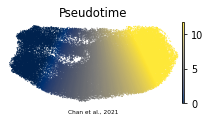

In [16]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=6, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Chan et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')